In [6]:
# Bibliotecas utilizadas

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# A equação de Bessel #

As **Funções de Bessel** são as soluções da EDO de segunda ordem denominada **Equação diferencial de Bessel**$,$

$$t^2\frac{d^2y}{{dt}^2} + t\frac{dy}{dt} + (t^2 - \alpha^2)y = 0\,,$$

onde $\alpha$ é um número complexo conhecido como **ordem** da equação.

### Resolução da equação de Bessel ###

Dividindo ambos os lados da equação de Bessel por $t^2$ ficamos com

$$\frac{d^2y}{{dt}^2} + \frac{1}{t}\frac{dy}{dt} + \left(1-\frac{\alpha^2}{t^2}\right)y = 0 \rightarrow p(t) = \frac{1}{t}\,,\,q(t) = 1-\frac{\alpha^2}{t^2}\,.$$

Como $tp(t) = 1$ e $t^2q(t) = t^2 - \alpha^2$ são analíticas em $t = 0$, então $t_0 = 0$ é um ponto singular regular da equação de Bessel e, portanto, ela possui uma solução da forma:

$$y(t) = \sum\limits_{k=0}^{\infty}a_k t^{k+r}\,,\,a_0 \neq 0\,,$$

assim:

$$\frac{dy}{dt} = \sum\limits_{k=0}^{\infty}(k+r)a_k t^{k+r-1}\,,$$
$$\frac{d^2y}{{dt}^2} = \sum\limits_{k=0}^{\infty}(k+r)(k+r-1)a_k t^{k+r-2}\,.$$

Substituindo na equação diferencial e agrupando os termos sob a potência $t^{k+r}$ obtemos a seguinte equação:

$$\sum\limits_{k=0}^{\infty}\left[(k+r)^2 - \alpha^2\right]a_k t^{k+r} + \sum\limits_{k=2}^{\infty}a_{k-2}t^{k+r} = 0\,,$$

como $a_0 \neq 0$, pela igualdade de polinômios extraimos que $r = \pm\alpha$, $a_1 = 0$ e escolhendo a raiz $r = \alpha$ para desenvolver:

$$a_k = \frac{-a_{k-2}}{k(k+2\alpha)}\,,\,k \geq 2\,.$$

Como $a_0 = 0$, então $a_3 = a_5 = a_7 = ... = 0$. Para os termos pares, fazendo $k = 2m\,,\, m = 1,2,3,...,$ ficamos com:

$$a_{2m} = \frac{-a_{2m-2}}{2m(2m+2\alpha)} = \frac{-a_{2m-2}}{2^2 m(m+\alpha)}\,.$$

Iterando a ocorrência a partir de $a_0$, nota-se que:

$$a_{2m} = \frac{(-1)^m a_0}{2^{2m}m!(1+\alpha)(2+\alpha)...(m+\alpha)}$$
$$a_{2m} = \frac{(-1)^m a_0}{2^{2m}m!\prod\limits_{j=1}^{m}(j+\alpha)}\,,$$

utilizando a seguinte propriedade da função Gamma:

$$\Gamma(m+\alpha+1) = \Gamma(\alpha + 1)\prod\limits_{j=1}^{m}(j+\alpha)\,,$$

podemos escrever $a_{2m}$ como:

$$a_{2m} = \frac{(-1)^m a_0 \Gamma(\alpha + 1)}{2^{2m}m!\Gamma(m+\alpha+1)}$$

e a solução da equação fica da forma:

$$y(t) = \sum\limits_{k=0}^{\infty}a_k t^{k+r} = \sum\limits_{m=0}^{\infty}a_{2m}t^{2m+\alpha}$$
$$y(t) = a_0\Gamma(\alpha+1)\sum\limits_{m=0}^{\infty}\frac{(-1)^m t^{2m+\alpha}}{2^{2m}m!\Gamma(m+\alpha+1)}\,,$$

como $a_0$ é uma constante não nula qualquer, escolhendo:

$$a_0 = \frac{1}{2^\alpha \Gamma(\alpha+1)}$$

chegamos a forma das **Funções de Bessel de primeira espécie**:

$$y(t) = J_\alpha (t) = \sum\limits_{m=0}^{\infty}\frac{(-1)^m}{m!\Gamma(m+\alpha+1)}\left(\frac{t}{2}\right)^{2m+\alpha}\,.$$

A função $J_\alpha (t)$ é denominada **Função de Bessel de primeira espécie de ordem $\alpha$**.

## Visualizando as funções de Bessel da primeira espécie ##

In [7]:
def fatorial(n):
    if n == 0:
        return 1
    else:
        produto = 1
        for k in range(1, n + 1, 1):
            produto *= k
        return produto

def integrando_funcao_Gamma(x, z):
    exp = np.exp(-x)
    polinomio = np.power(x, z - 1)
    return polinomio * exp

def funcao_Gamma(Z):
    if np.isscalar(Z):
        Z = np.array([Z], dtype=float)
    resultados = []
    for z in Z:
        # Polos da função Gamma (0, -1, -2, ...)
        if z <= 0 and np.isclose(z, np.round(z), rtol=0, atol=1e-12):
            resultados.append(np.inf)
            continue

        # Desloca z para o intervalo [1, 2) onde a integral é suave e bem comportada, aproveitando a propriedade \Gamma(z+1) = z\Gamma(z)
        multiplicador = 1.0
        while z < 1:
            multiplicador /= z
            z += 1
        while z >= 2:
            z -= 1
            multiplicador *= z

        def f(x):
            return integrando_funcao_Gamma(x, z)
        resultado, erro = quad(f, 0, np.inf)
        resultados.append(resultado * multiplicador)

    resultados = np.array(resultados)
    if len(resultados) == 1:
        return resultados[0]
    return resultados

def J(t, alpha, M=50):
    if not (np.isscalar(alpha)):
        raise ValueError('\u03B1 deve ser um escalar')
    soma = 0
    for m in range(0, M + 1, 1):
        denominador2 = funcao_Gamma(m + alpha + 1)
        
        # Se Gamma divergir (polo), 1/Gamma = 0; pula o termo para evitar NaN em t = 0
        if np.isinf(denominador2):
            continue

        sinal = (-1)**m
        denominador1 = fatorial(m)
        denominador = denominador1 * denominador2

        numerador = np.power(t / 2, 2 * m + alpha)

        soma += sinal * numerador / denominador

    return soma

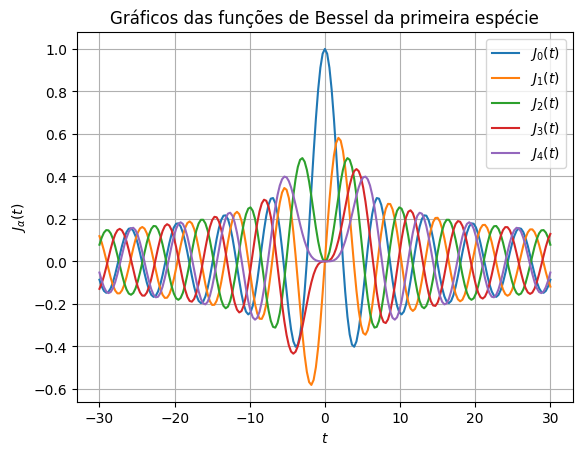

In [8]:
t0 = -30
tf = 30
M = 50

lista_alpha = [0,1,2,3,4]
t = np.linspace(t0, tf,201)

lista_J = []
for alpha in lista_alpha:
    J_alpha = J(t,alpha,M)
    lista_J.append(J_alpha)

for k in range(0, len(lista_alpha),1):
    if lista_alpha[k].is_integer():
        plt.plot(t, lista_J[k], label = r'$J_{%d}(t)$' %(lista_alpha[k]))
    else:
        plt.plot(t, lista_J[k], label = r'$J_{%.1f}(t)$' %(lista_alpha[k]))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$J_{\alpha}(t)$')
plt.title('Gráficos das funções de Bessel da primeira espécie')
plt.legend(loc = 'best')
plt.show()

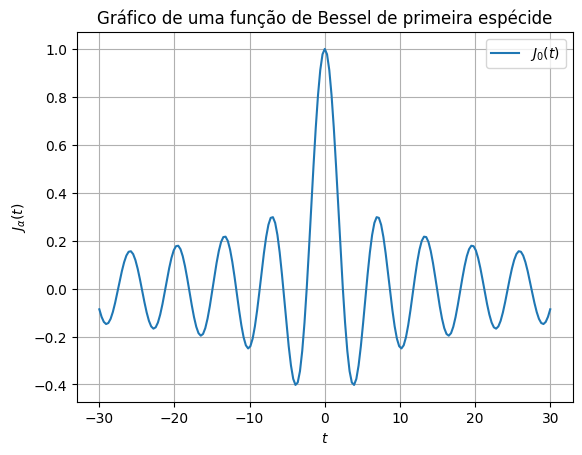

In [9]:
M = 50

alpha = 0
J_alpha = J(t, alpha, M)
if alpha.is_integer():
    plt.plot(t, J_alpha, label = r'$J_{%d}(t)$' %(alpha))
else:
    plt.plot(t, lista_J[k], label = r'$J_{%d}(t)$' %(alpha))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$J_{\alpha}(t)$')
plt.title('Gráfico de uma função de Bessel de primeira espécide')
plt.legend(loc = 'best')
plt.show()

# Propriedades das funções de Bessel de primeira espécie #

A seguir, são apresentadas algumas propriedades das funções de Bessel de primeira espécie:

##### 1 - Paridade em relação ao argumento

Sendo $n$ um número inteiro, então:

$$J_n(-t) = (-1)^n J_n(t)\,.$$

##### 2 - Paridade em relação a ordem

Sendo $n$ um número inteiro, então:

$$J_{-n}(t) = (-1)^nJ(t)\,.$$

##### 3 - Primeira identidade diferencial

$$\frac{d}{dt}[t^\alpha J_\alpha(t)] = t^\alpha J_{\alpha-1}(t)\,.$$

##### 4 - Segunda identidade diferencial

$$\frac{d}{dt}[t^{-\alpha}J_\alpha(t)] = -t^{-\alpha}J_{\alpha+1}(t)\,.$$

##### 5 - Relação de recorrência algébrica

$$J_{\alpha-1}(t)+J_{\alpha+1}(t) = \frac{2\alpha}{t}J_\alpha(t)\,.$$

##### 6 - Relação da derivada

$$J_{\alpha-1}(t) - J_{\alpha+1}(t) = 2\frac{dJ_\alpha(t)}{dt}\,.$$

Algumas dessas propriedades podem ser visualizadas graficamente a seguir:

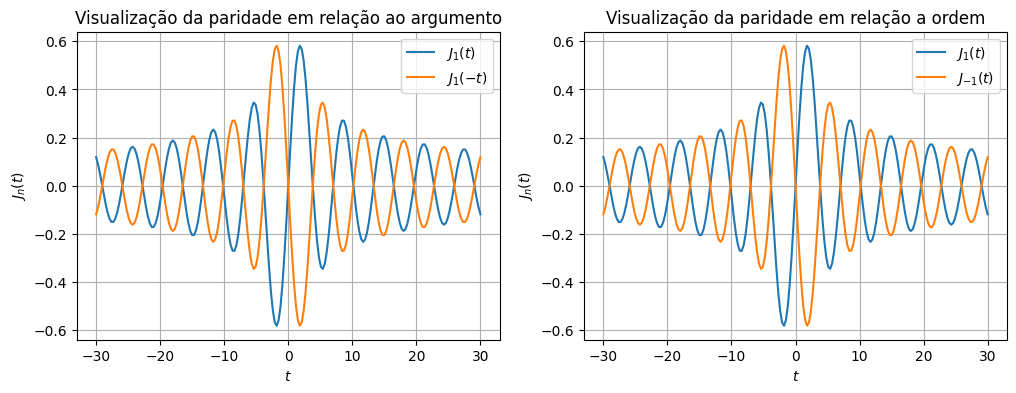

In [10]:
M = 50

n = 1

fig, ax = plt.subplots(1,2, figsize = (12,4))

ax[0].plot(t, J(t, n, M), label = r'$J_{%d}(t)$' %(n))
ax[0].plot(t, J(-t, n, M), label = r'$J_{%d}(-t)$' %(n))
ax[0].grid(True)
ax[0].set_xlabel('$t$')
ax[0].set_ylabel(r'$J_{n}(t)$')
ax[0].set_title('Visualização da paridade em relação ao argumento')
ax[0].legend(loc = 'best')

ax[1].plot(t, J(t, n, M), label = r'$J_{%d}(t)$' %(n))
ax[1].plot(t, J(t, -n, M), label = r'$J_{-%d}(t)$' %(n))
ax[1].grid(True)
ax[1].set_xlabel('$t$')
ax[1].set_ylabel(r'$J_{n}(t)$')
ax[1].set_title('Visualização da paridade em relação a ordem')
ax[1].legend(loc = 'best')

plt.show()